# Salary Prediction Model

Three approaches compared:
1. **Baseline** — 6 original features, all 173K rows
2. **Enriched** — 11 features (education, industry, work_setting, experience_years), 102K rows
3. **Ensemble** — weighted average of both models

In [11]:
import pandas as pd
import numpy as np
import os
import time

os.chdir(r"D:\Desktop\Data Science Salary Dashboard")
PROCESSED = "data/processed"

## 1. Load Preprocessed Data

In [12]:
df_orig = pd.read_csv(f"{PROCESSED}/salary_original_only.csv")
df_enriched = pd.read_csv(f"{PROCESSED}/salary_model_ready.csv")

print(f"Original-only:  {df_orig.shape[0]:,} rows, {df_orig.shape[1]} cols")
print(f"Enriched:       {df_enriched.shape[0]:,} rows, {df_enriched.shape[1]} cols")
print(f"\nEnriched columns: {list(df_enriched.columns)}")

Original-only:  173,453 rows, 7 cols
Enriched:       102,000 rows, 41 cols

Enriched columns: ['work_year', 'job_title', 'experience_level', 'experience_years', 'employment_type', 'salary_in_usd', 'company_location', 'company_size', 'education_level', 'work_setting', 'industry', 'primary_skills', 'remote_ratio', 'ai_specialization', 'cost_of_living_index', 'job_security_score', 'work_life_balance_score', 'ai_adoption_score', 'bonus_usd', 'job_category', 'ai_adoption_level', 'gender', 'job_satisfaction', 'years_at_company', 'source', 'skill_javascript', 'skill_rust', 'skill_kubernetes', 'skill_sql', 'skill_aws', 'skill_hugging_face', 'skill_scala', 'skill_c__', 'skill_airflow', 'skill_pytorch', 'skill_hadoop', 'skill_excel', 'skill_kafka', 'skill_tableau', 'skill_r', 'skill_count']


C:\Users\DELL\AppData\Local\Temp\ipykernel_26968\4050080761.py:2: DtypeWarning: Columns (11) have mixed types. Specify dtype option on import or set low_memory=False.
  df_enriched = pd.read_csv(f"{PROCESSED}/salary_model_ready.csv")


## 2. MODEL A — Baseline (6 original features, all sources)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

BASE_FEATURES = ["work_year", "experience_level", "employment_type",
                 "job_title", "company_size", "company_location"]
TARGET = "salary_in_usd"

X_a = df_orig[BASE_FEATURES].copy()
y_a = df_orig[TARGET].copy()

X_a_train, X_a_test, y_a_train, y_a_test = train_test_split(
    X_a, y_a, test_size=0.2, random_state=42
)

numeric_a = ["work_year"]
categorical_a = [c for c in BASE_FEATURES if c not in numeric_a]

preprocessor_a = ColumnTransformer(transformers=[
    ("num", "passthrough", numeric_a),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_a),
])

model_a = Pipeline(steps=[
    ("preprocessor", preprocessor_a),
    ("regressor", RandomForestRegressor(n_estimators=200, random_state=42,
                                         min_samples_leaf=2, n_jobs=-1)),
])

t0 = time.time()
model_a.fit(X_a_train, y_a_train)
time_a = time.time() - t0

preds_a = model_a.predict(X_a_test)
r2_a = r2_score(y_a_test, preds_a)
mae_a = mean_absolute_error(y_a_test, preds_a)
rmse_a = np.sqrt(mean_squared_error(y_a_test, preds_a))

print(f"Model A (Baseline)")
print(f"  Train: {X_a_train.shape[0]:,} rows | Test: {X_a_test.shape[0]:,} rows")
print(f"  Time:  {time_a:.1f}s")
print(f"  R²:    {r2_a:.3f}")
print(f"  MAE:   ${mae_a:,.2f}")
print(f"  RMSE:  ${rmse_a:,.2f}")

## 3. MODEL B — Enriched (11 features, ai_jobs + tech)

In [ ]:
ENRICHED_FEATURES = [
    "work_year", "experience_level", "employment_type",
    "job_title", "company_size", "company_location",
    "education_level", "work_setting", "industry", "experience_years",
]

X_b = df_enriched[ENRICHED_FEATURES].copy()
y_b = df_enriched[TARGET].copy()

X_b_train, X_b_test, y_b_train, y_b_test = train_test_split(
    X_b, y_b, test_size=0.2, random_state=42
)

numeric_b = ["work_year", "experience_years"]
categorical_b = [c for c in ENRICHED_FEATURES if c not in numeric_b]

preprocessor_b = ColumnTransformer(transformers=[
    ("num", "passthrough", numeric_b),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_b),
])

model_b = Pipeline(steps=[
    ("preprocessor", preprocessor_b),
    ("regressor", RandomForestRegressor(n_estimators=200, random_state=42,
                                         min_samples_leaf=2, n_jobs=-1)),
])

t0 = time.time()
model_b.fit(X_b_train, y_b_train)
time_b = time.time() - t0

preds_b = model_b.predict(X_b_test)
r2_b = r2_score(y_b_test, preds_b)
mae_b = mean_absolute_error(y_b_test, preds_b)
rmse_b = np.sqrt(mean_squared_error(y_b_test, preds_b))

print(f"Model B (Enriched)")
print(f"  Train: {X_b_train.shape[0]:,} rows | Test: {X_b_test.shape[0]:,} rows")
print(f"  Time:  {time_b:.1f}s")
print(f"  R²:    {r2_b:.3f}")
print(f"  MAE:   ${mae_b:,.2f}")
print(f"  RMSE:  ${rmse_b:,.2f}")

Model B (Enriched)
  Train: 81,600 rows | Test: 20,400 rows
  Time:  168.2s
  R²:    0.900
  MAE:   $11,522.99
  RMSE:  $17,571.52


## 4. MODEL C — Ensemble (weighted average)

In [ ]:
# Find overlap: rows in enriched that also exist in original
# Use the enriched test set indices to align predictions
overlap_cols = ["work_year", "job_title", "experience_level", "employment_type",
                "salary_in_usd", "company_location", "company_size"]

# Get the enriched test rows
df_enriched_test = df_enriched.loc[X_b_test.index].copy()

# Predict with Model A on the same rows Model B was tested on
preds_a_on_b = model_a.predict(df_enriched_test[BASE_FEATURES])

# Ensemble: weighted average (tuned weights)
# Model B has more signal from enriched features, give it more weight
weights = np.linspace(0.3, 0.7, 20)  # test weight_b from 0.3 to 0.7
best_r2 = -999
best_w = 0.5
for w in weights:
    combined = w * preds_b + (1 - w) * preds_a_on_b
    score = r2_score(y_b_test, combined)
    if score > best_r2:
        best_r2 = score
        best_w = w

preds_c = best_w * preds_b + (1 - best_w) * preds_a_on_b
r2_c = r2_score(y_b_test, preds_c)
mae_c = mean_absolute_error(y_b_test, preds_c)
rmse_c = np.sqrt(mean_squared_error(y_b_test, preds_c))

print(f"Model C (Ensemble)")
print(f"  Weight (enriched): {best_w:.2f} | Weight (baseline): {1-best_w:.2f}")
print(f"  R²:    {r2_c:.3f}")
print(f"  MAE:   ${mae_c:,.2f}")
print(f"  RMSE:  ${rmse_c:,.2f}")

Model C (Ensemble)
  Weight (enriched): 0.53 | Weight (baseline): 0.47
  R²:    0.914
  MAE:   $10,938.13
  RMSE:  $16,278.98


## 5. Comparison

In [ ]:
results = pd.DataFrame({
    "Model": ["A: Baseline (6 feat, 173K)", "B: Enriched (11 feat, 102K)", "C: Ensemble"],
    "R²": [r2_a, r2_b, r2_c],
    "MAE": [mae_a, mae_b, mae_c],
    "RMSE": [rmse_a, rmse_b, rmse_c],
    "Train Rows": [X_a_train.shape[0], X_b_train.shape[0], f"{X_b_train.shape[0]} + {X_a_train.shape[0]}"],
    "Features": [len(BASE_FEATURES), len(ENRICHED_FEATURES), "both"],
})
results["MAE"] = results["MAE"].apply(lambda x: f"${x:,.0f}")
results["RMSE"] = results["RMSE"].apply(lambda x: f"${x:,.0f}")
results["R²"] = results["R²"].apply(lambda x: f"{x:.3f}")
print(results.to_string(index=False))

                      Model    R²     MAE    RMSE     Train Rows Features
 A: Baseline (6 feat, 173K) 0.571 $28,066 $45,676         138762        6
B: Enriched (11 feat, 102K) 0.900 $11,523 $17,572          81600       10
                C: Ensemble 0.914 $10,938 $16,279 81600 + 138762     both


## 6. Feature Importance (Enriched Model)

Feature Importance (Enriched Model):
original_feature
experience_years    0.347076
company_location    0.320231
experience_level    0.146412
job_title           0.082615
industry            0.031497
company_size        0.020075
work_year           0.015167
education_level     0.015032
employment_type     0.014412
work_setting        0.007484
Name: importance, dtype: float64


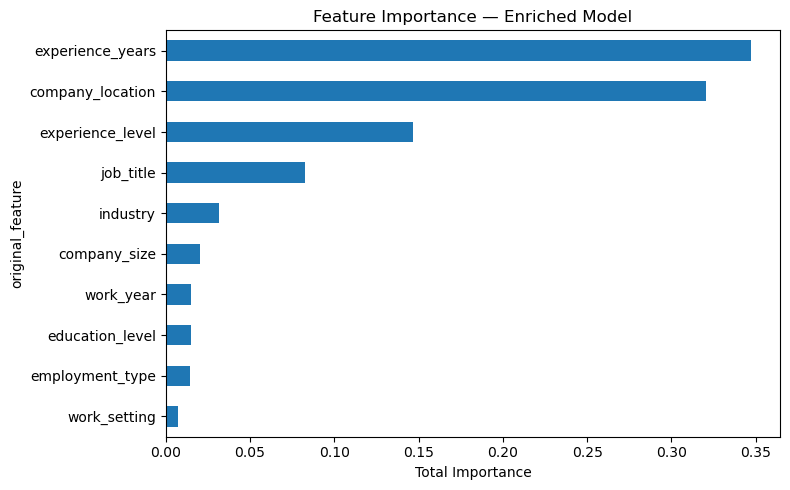

In [ ]:
import matplotlib.pyplot as plt

feature_names = model_b.named_steps["preprocessor"].get_feature_names_out()
importances = model_b.named_steps["regressor"].feature_importances_

imp_df = pd.DataFrame({"feature": feature_names, "importance": importances})

def original_feature(name):
    for col in categorical_b:
        if f"cat__{col}_" in name:
            return col
    return name.replace("num__", "")

imp_df["original_feature"] = imp_df["feature"].apply(original_feature)
grouped_imp = imp_df.groupby("original_feature")["importance"].sum().sort_values(ascending=False)

print("Feature Importance (Enriched Model):")
print(grouped_imp)

plt.figure(figsize=(8, 5))
grouped_imp.plot(kind="barh")
plt.gca().invert_yaxis()
plt.xlabel("Total Importance")
plt.title("Feature Importance — Enriched Model")
plt.tight_layout()
plt.show()

## 7. Feature Importance (Baseline Model)

Feature Importance (Baseline Model):
original_feature
company_location    0.454461
experience_level    0.292518
job_title           0.188341
work_year           0.026395
company_size        0.025164
employment_type     0.013121
Name: importance, dtype: float64


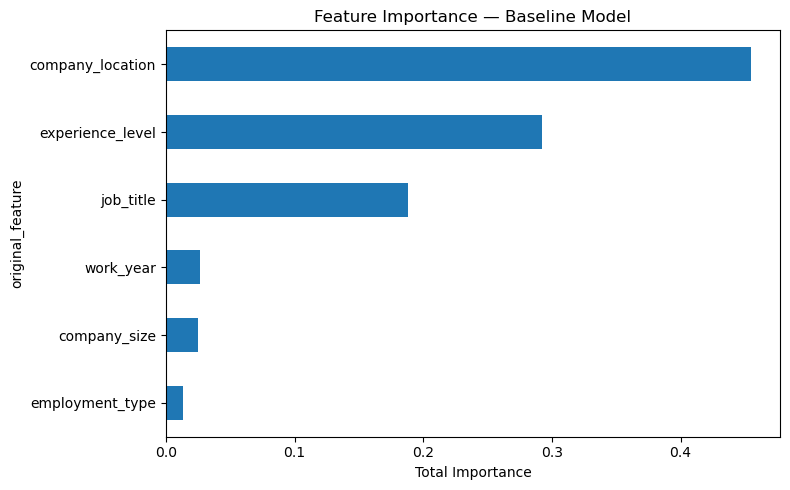

In [ ]:
feature_names_a = model_a.named_steps["preprocessor"].get_feature_names_out()
importances_a = model_a.named_steps["regressor"].feature_importances_

imp_df_a = pd.DataFrame({"feature": feature_names_a, "importance": importances_a})

def original_feature_a(name):
    for col in categorical_a:
        if f"cat__{col}_" in name:
            return col
    return name.replace("num__", "")

imp_df_a["original_feature"] = imp_df_a["feature"].apply(original_feature_a)
grouped_imp_a = imp_df_a.groupby("original_feature")["importance"].sum().sort_values(ascending=False)

print("Feature Importance (Baseline Model):")
print(grouped_imp_a)

plt.figure(figsize=(8, 5))
grouped_imp_a.plot(kind="barh")
plt.gca().invert_yaxis()
plt.xlabel("Total Importance")
plt.title("Feature Importance — Baseline Model")
plt.tight_layout()
plt.show()

## 8. Residual Analysis

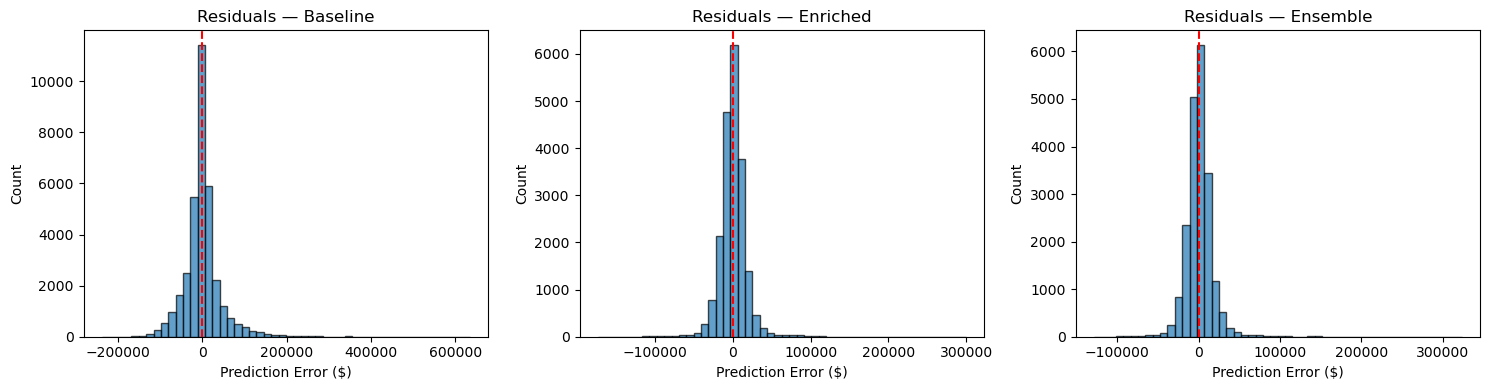

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, preds, title in zip(axes,
    [preds_a, preds_b, preds_c],
    ["Baseline", "Enriched", "Ensemble"]):
    if title == "Baseline":
        resid = y_a_test - preds
    else:
        resid = y_b_test - preds
    ax.hist(resid, bins=50, edgecolor="black", alpha=0.7)
    ax.set_title(f"Residuals — {title}")
    ax.set_xlabel("Prediction Error ($)")
    ax.set_ylabel("Count")
    ax.axvline(0, color="red", linestyle="--")

plt.tight_layout()
plt.show()

## 9. Predicted vs Actual

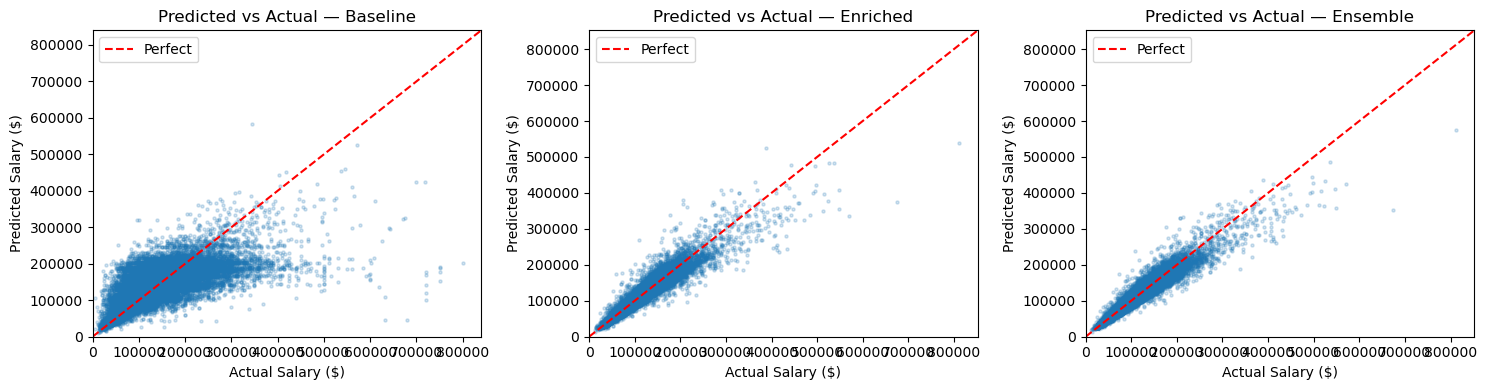

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, preds, y_test, title in zip(axes,
    [preds_a, preds_b, preds_c],
    [y_a_test, y_b_test, y_b_test],
    ["Baseline", "Enriched", "Ensemble"]):
    ax.scatter(y_test, preds, alpha=0.2, s=5)
    lims = [0, max(y_test.max(), preds.max()) * 1.05]
    ax.plot(lims, lims, "r--", label="Perfect")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel("Actual Salary ($)")
    ax.set_ylabel("Predicted Salary ($)")
    ax.set_title(f"Predicted vs Actual — {title}")
    ax.legend()

plt.tight_layout()
plt.show()